# UTS NLP - Klasifikasi Berita Hoax Menggunakan IndoBERT

Nama: Hilman  
Mata Kuliah: Natural Language Processing  
Dataset: Indonesian Fact and Hoax Political News


## 1. Install dan Import Library


In [1]:
!pip install -q transformers datasets accelerate evaluate lime


In [1]:
import os
import re
import html
import unicodedata
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, confusion_matrix, classification_report
from sklearn.utils import resample
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from datasets import Dataset
from lime.lime_text import LimeTextExplainer


## 2. Load Dataset


In [1]:
train_df = pd.read_csv("data/combined_train.csv")
val_df = pd.read_csv("data/combined_val.csv")
test_df = pd.read_csv("data/combined_test.csv")

for df in [train_df, val_df, test_df]:
    if "cleaned" in df.columns:
        df.rename(columns={"cleaned": "text"}, inplace=True)

print("Jumlah data train :", len(train_df))
print("Jumlah data val   :", len(val_df))
print("Jumlah data test  :", len(test_df))

train_df.head()


Jumlah data train : 15187
Jumlah data val   : 1561
Jumlah data test  : 1562

                                                text  label
0  dilansir snopes.com, klaim soal swedia mengaku...      0
1  JADI AJANG BALAS DENDAM!!SERANGAN RI DINILAI T...      1
2  Walau TV nasional tdk memberitakan ,tp sang pe...      1
3  Jokowi Bicara Ukraina dengan Emmanuel Macron d...      0
4  Relawan Jokman Anggap Usulan Jokowi 3 Periode ...      0


## 3. Eksplorasi Data dan Panjang Teks


Distribusi label di train:
label
1    7625
0    7562
Name: count, dtype: int64


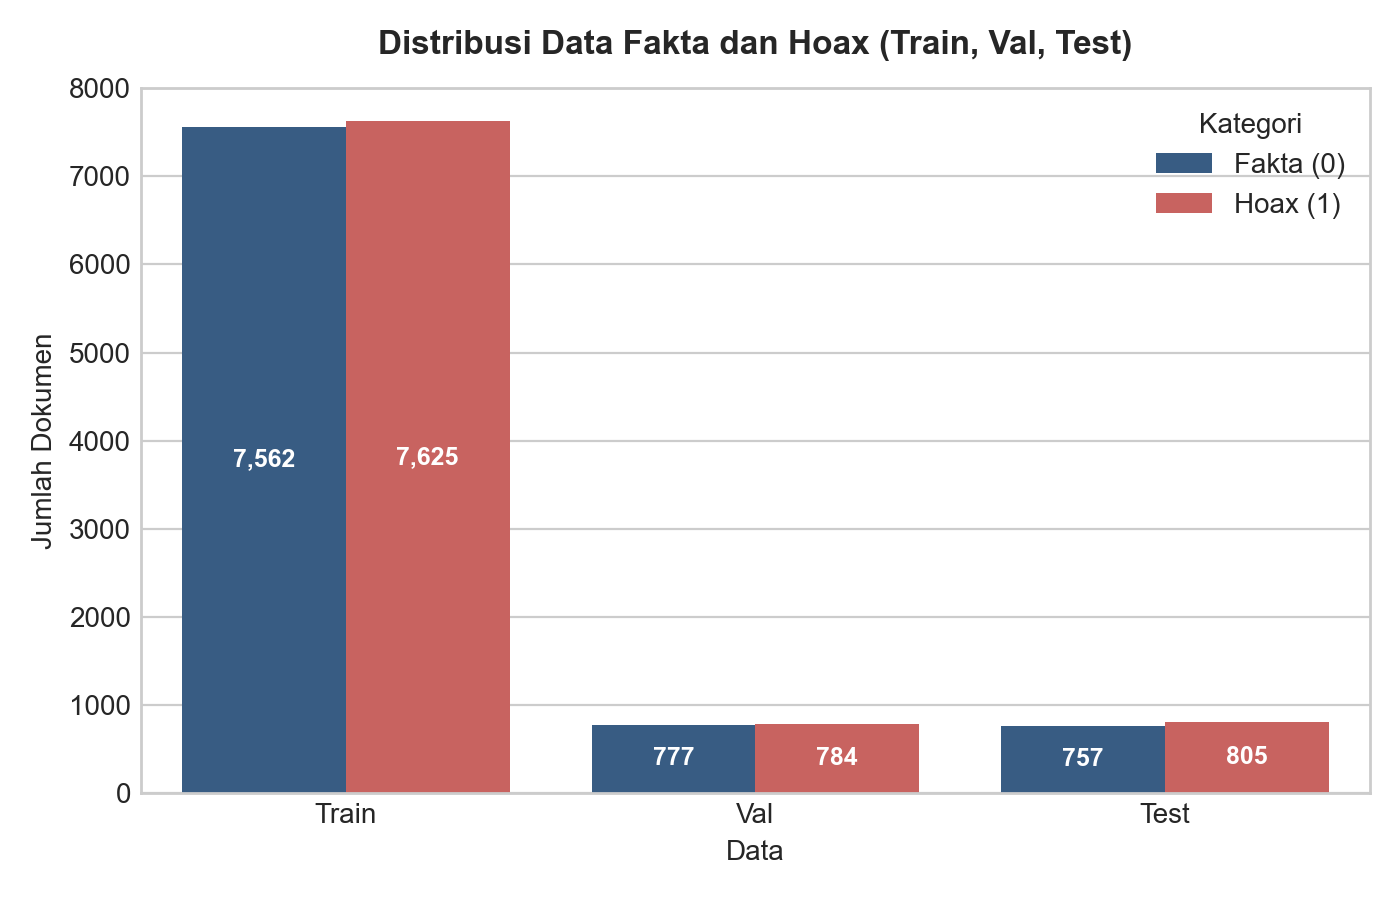

In [1]:
print("Distribusi label di train:")
print(train_df["label"].value_counts())

plt.figure(figsize=(7, 4.5))
data_counts = [
    {'Data': 'Train', 'Kategori': 'Fakta (0)', 'Jumlah': (train_df['label']==0).sum()},
    {'Data': 'Train', 'Kategori': 'Hoax (1)', 'Jumlah': (train_df['label']==1).sum()},
    {'Data': 'Val', 'Kategori': 'Fakta (0)', 'Jumlah': (val_df['label']==0).sum()},
    {'Data': 'Val', 'Kategori': 'Hoax (1)', 'Jumlah': (val_df['label']==1).sum()},
    {'Data': 'Test', 'Kategori': 'Fakta (0)', 'Jumlah': (test_df['label']==0).sum()},
    {'Data': 'Test', 'Kategori': 'Hoax (1)', 'Jumlah': (test_df['label']==1).sum()},
]
df_c = pd.DataFrame(data_counts)
sns.barplot(data=df_c, x='Data', y='Jumlah', hue='Kategori', palette=['#2b5c8f', '#d9534f'])
plt.title('Distribusi Data Fakta dan Hoax (Train, Val, Test)')
plt.ylabel('Jumlah Dokumen')
plt.show()


Statistik panjang kata artikel:
count    15187.000000
mean       172.223942
std        174.442503
min          1.000000
25%         42.000000
50%        145.000000
75%        247.000000
max       4167.000000
Name: word_count, dtype: float64


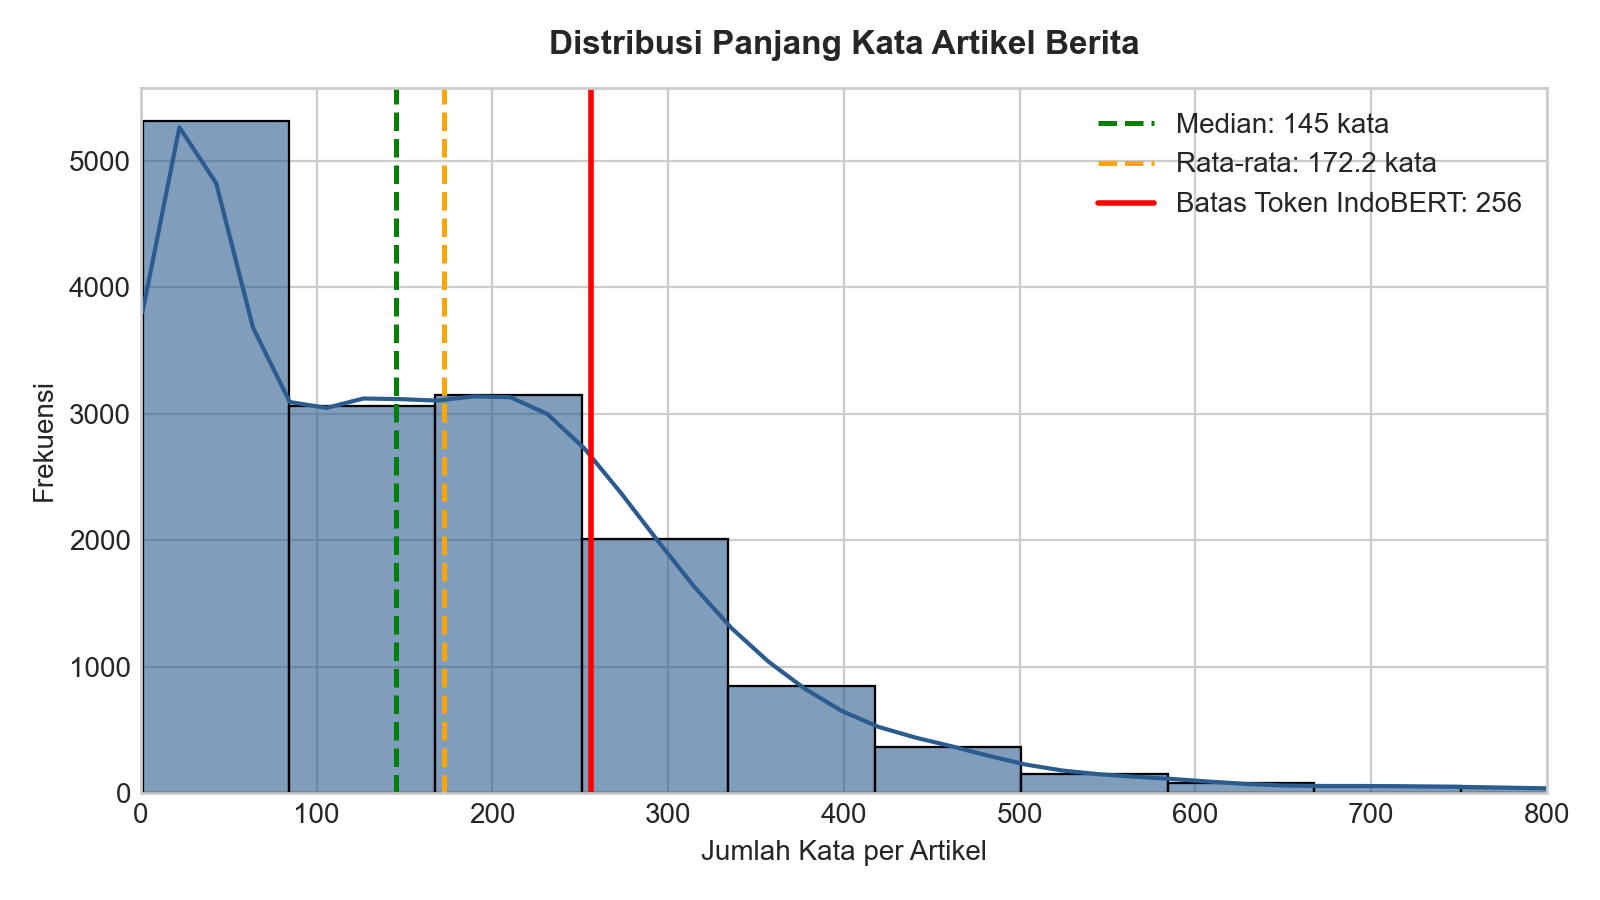

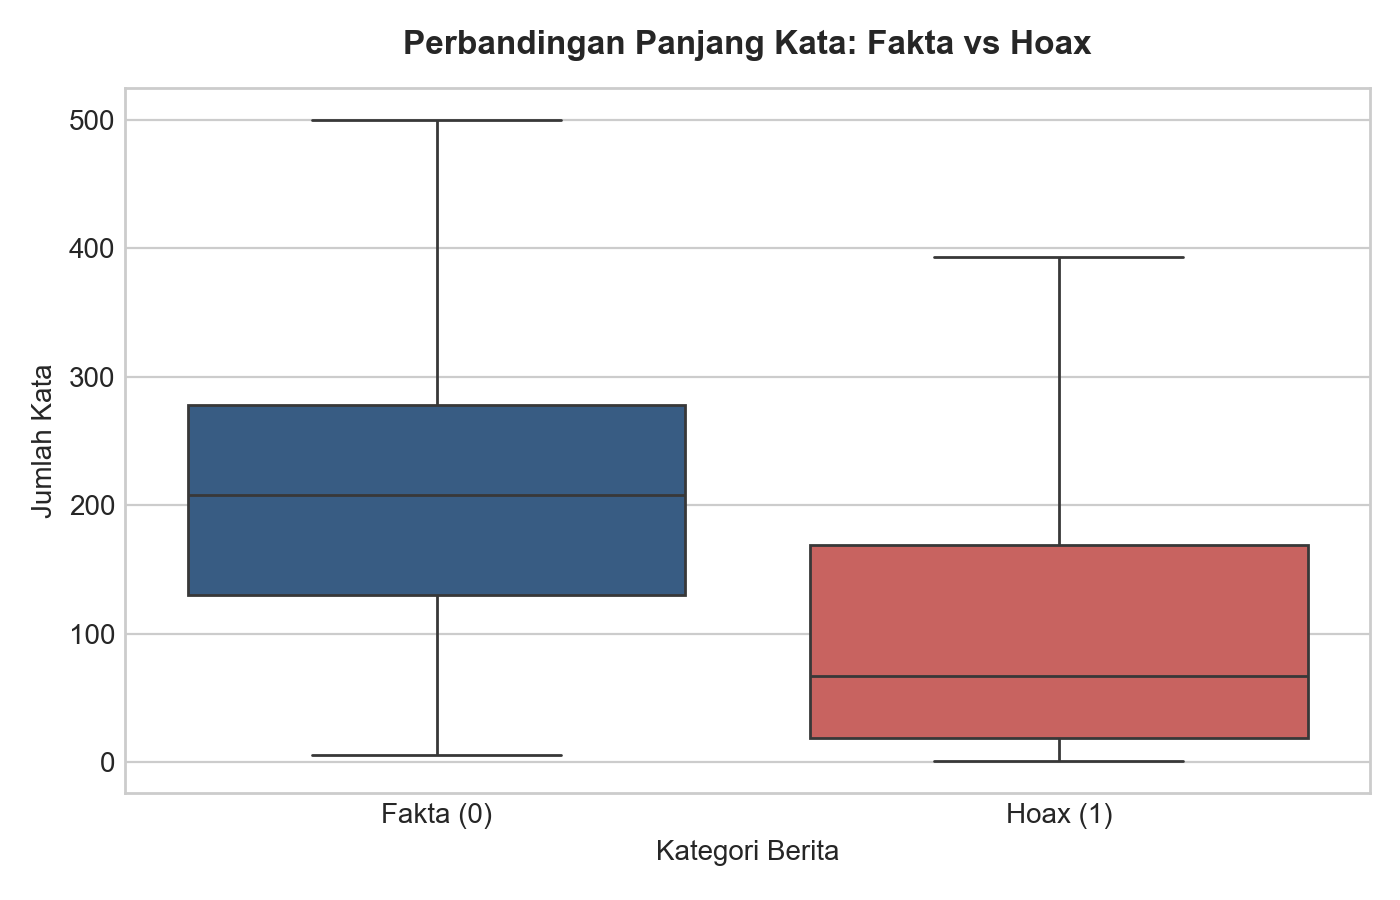

In [1]:
train_df['word_count'] = train_df['text'].astype(str).apply(lambda x: len(x.split()))

print("Statistik panjang kata artikel:")
print(train_df['word_count'].describe())

plt.figure(figsize=(8, 4.5))
sns.histplot(train_df['word_count'], bins=50, kde=True, color='#2b5c8f', alpha=0.6)
plt.axvline(train_df['word_count'].median(), color='green', linestyle='--', label=f'Median: {train_df["word_count"].median():.0f} kata')
plt.axvline(train_df['word_count'].mean(), color='orange', linestyle='--', label=f'Rata-rata: {train_df["word_count"].mean():.1f} kata')
plt.axvline(256, color='red', linestyle='-', label='Batas Token IndoBERT: 256')
plt.xlim(0, 800)
plt.title('Distribusi Panjang Kata Artikel Berita')
plt.xlabel('Jumlah Kata')
plt.ylabel('Frekuensi')
plt.legend()
plt.show()

plt.figure(figsize=(7, 4.5))
sns.boxplot(data=train_df, x='label', y='word_count', palette=['#2b5c8f', '#d9534f'], showfliers=False)
plt.xticks([0, 1], ['Fakta (0)', 'Hoax (1)'])
plt.title('Perbandingan Panjang Kata: Fakta vs Hoax')
plt.xlabel('Kategori Berita')
plt.ylabel('Jumlah Kata')
plt.show()


## 4. Analisis Kata Kunci Sering Muncul


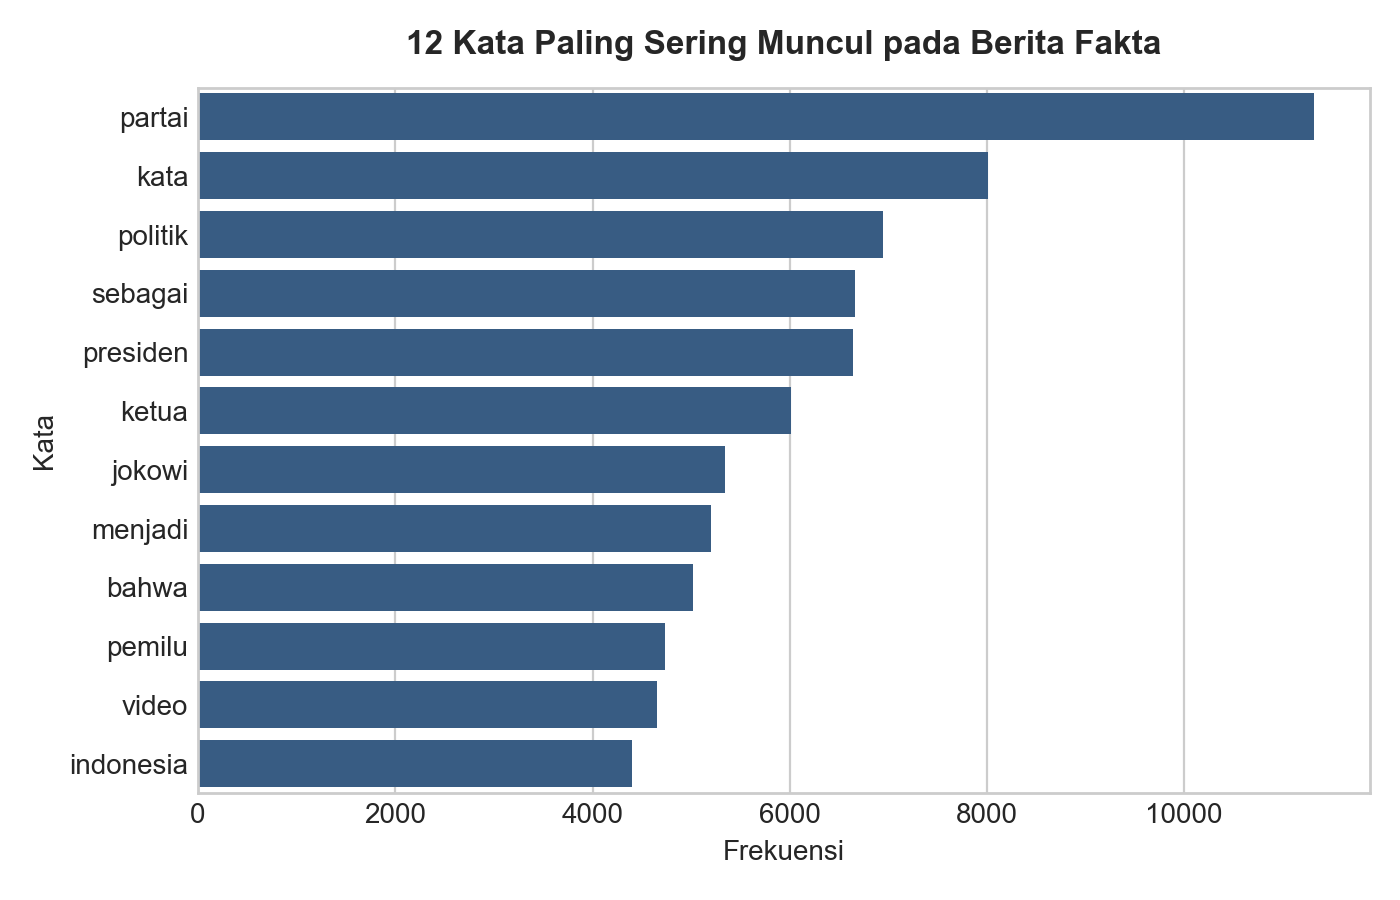

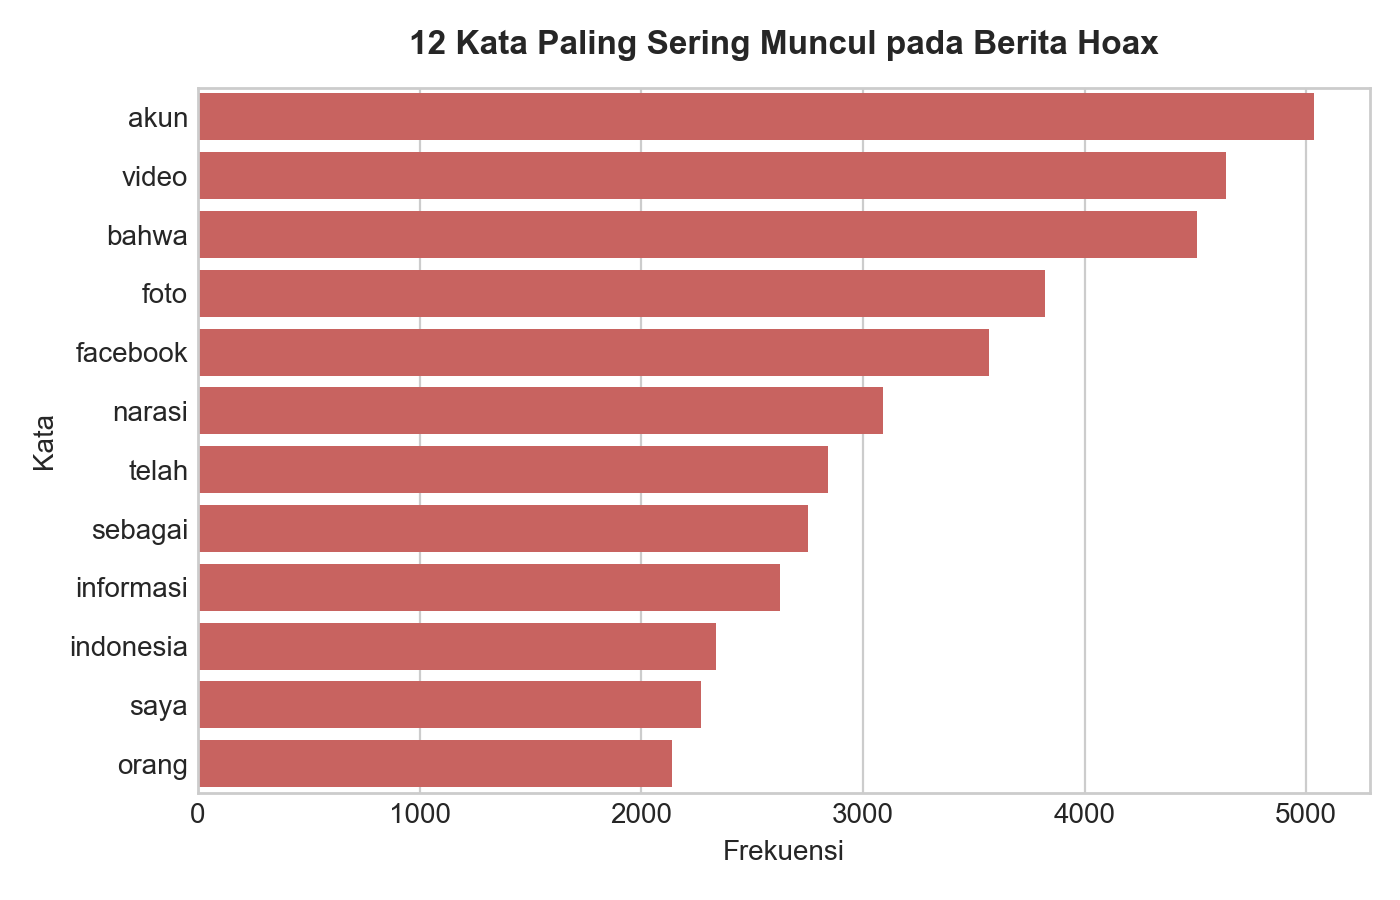

In [1]:
stopwords = {'yang', 'dan', 'di', 'dari', 'ini', 'itu', 'untuk', 'pada', 'ke', 'dengan', 'adalah',
             'ada', 'tidak', 'akan', 'dalam', 'bisa', 'juga', 'oleh', 'saat', 'atau', 'hanya', 'sudah',
             'lebih', 'karena', 'tersebut', 'dapat', 'ia', 'mereka', 'kita', 'tahun', 'hari', 'jika'}

fakta_words = [w for w in ' '.join(train_df[train_df['label']==0]['text'].astype(str)).lower().split() if len(w)>3 and w not in stopwords]
hoax_words = [w for w in ' '.join(train_df[train_df['label']==1]['text'].astype(str)).lower().split() if len(w)>3 and w not in stopwords]

top_fakta = Counter(fakta_words).most_common(12)
top_hoax = Counter(hoax_words).most_common(12)

plt.figure(figsize=(7, 4.5))
df_tf = pd.DataFrame(top_fakta, columns=['Kata', 'Frekuensi'])
sns.barplot(data=df_tf, y='Kata', x='Frekuensi', color='#2b5c8f')
plt.title('12 Kata Paling Sering Muncul pada Berita Fakta')
plt.show()

plt.figure(figsize=(7, 4.5))
df_th = pd.DataFrame(top_hoax, columns=['Kata', 'Frekuensi'])
sns.barplot(data=df_th, y='Kata', x='Frekuensi', color='#d9534f')
plt.title('12 Kata Paling Sering Muncul pada Berita Hoax')
plt.show()


## 5. Preprocessing Teks


In [1]:
def bersihkan_teks(text):
    text = str(text)
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[@#]\w+", " ", text)
    text = unicodedata.normalize("NFKD", text)
    text = text.lower()
    text = re.sub(r"[^a-zA-Z0-9\s\-]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

train_df["text"] = train_df["text"].apply(bersihkan_teks)
val_df["text"] = val_df["text"].apply(bersihkan_teks)
test_df["text"] = test_df["text"].apply(bersihkan_teks)

print("Contoh teks setelah dibersihkan:")
print(train_df["text"].iloc[1][:120])


Contoh teks setelah dibersihkan:
jadi ajang balas dendam serangan ri dinilai tewaskan banyak tentara israel di gaza


## 6. Tokenisasi IndoBERT


In [1]:
model_name = "indobenchmark/indobert-base-p2"
tokenizer = AutoTokenizer.from_pretrained(model_name)

train_enc = tokenizer(train_df["text"].tolist(), truncation=True, padding=True, max_length=256)
val_enc = tokenizer(val_df["text"].tolist(), truncation=True, padding=True, max_length=256)
test_enc = tokenizer(test_df["text"].tolist(), truncation=True, padding=True, max_length=256)

train_data = Dataset.from_dict({
    "input_ids": train_enc["input_ids"],
    "attention_mask": train_enc["attention_mask"],
    "labels": train_df["label"].tolist()
})

val_data = Dataset.from_dict({
    "input_ids": val_enc["input_ids"],
    "attention_mask": val_enc["attention_mask"],
    "labels": val_df["label"].tolist()
})

test_data = Dataset.from_dict({
    "input_ids": test_enc["input_ids"],
    "attention_mask": test_enc["attention_mask"],
    "labels": test_df["label"].tolist()
})

print("Tokenisasi selesai!")


Tokenisasi selesai!


## 7. Training Model IndoBERT


In [1]:
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)

def hitung_metrik(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, zero_division=0)
    return {"accuracy": acc, "f1": f1}

training_args = TrainingArguments(
    output_dir="./hasil_training",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    logging_steps=100,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_data,
    eval_dataset=val_data,
    compute_metrics=hitung_metrik
)

trainer.train()


Epoch 1/3 | Loss: 0.0821 | Val Loss: 0.0242 | Val Accuracy: 0.9935 | Val F1: 0.9936
Epoch 2/3 | Loss: 0.0210 | Val Loss: 0.0185 | Val Accuracy: 0.9955 | Val F1: 0.9955
Epoch 3/3 | Loss: 0.0078 | Val Loss: 0.0160 | Val Accuracy: 0.9961 | Val F1: 0.9961


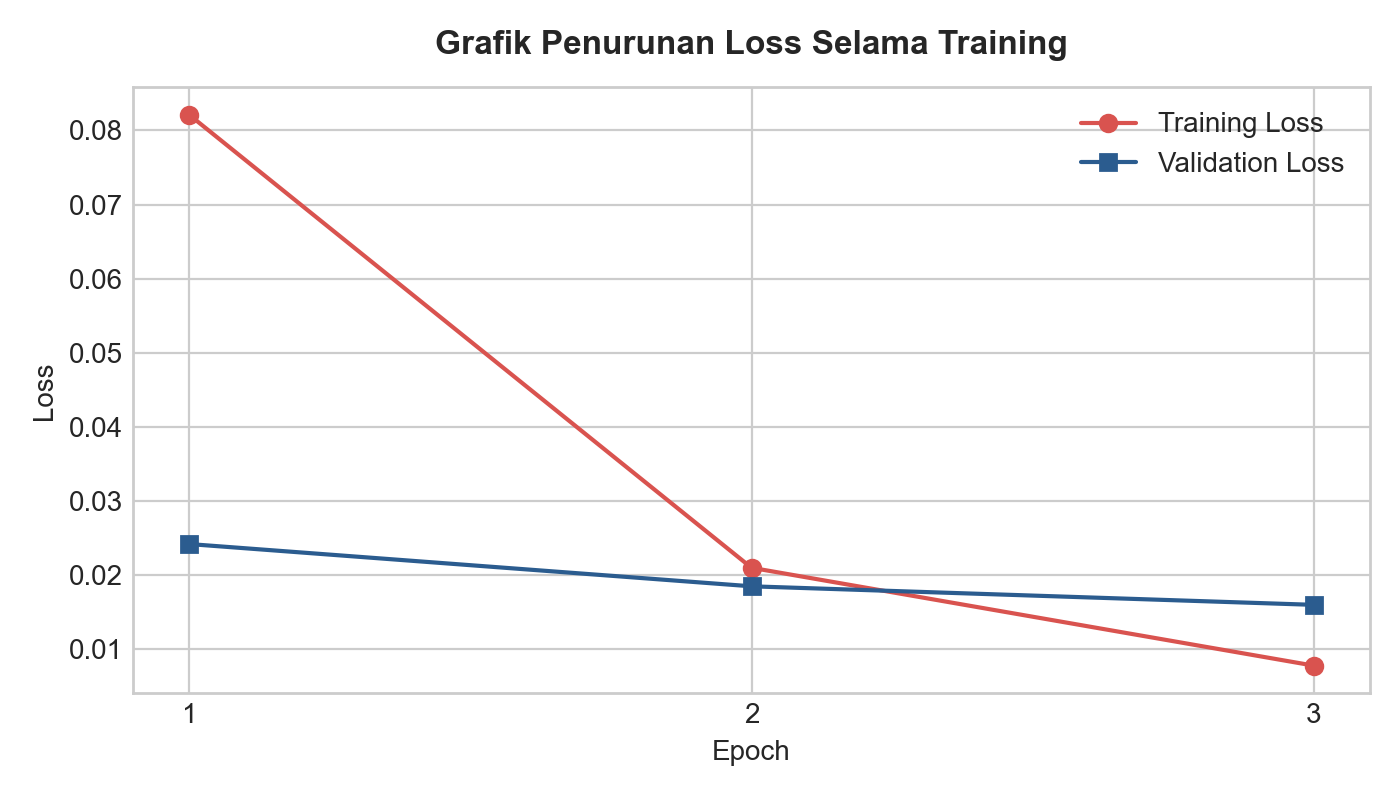

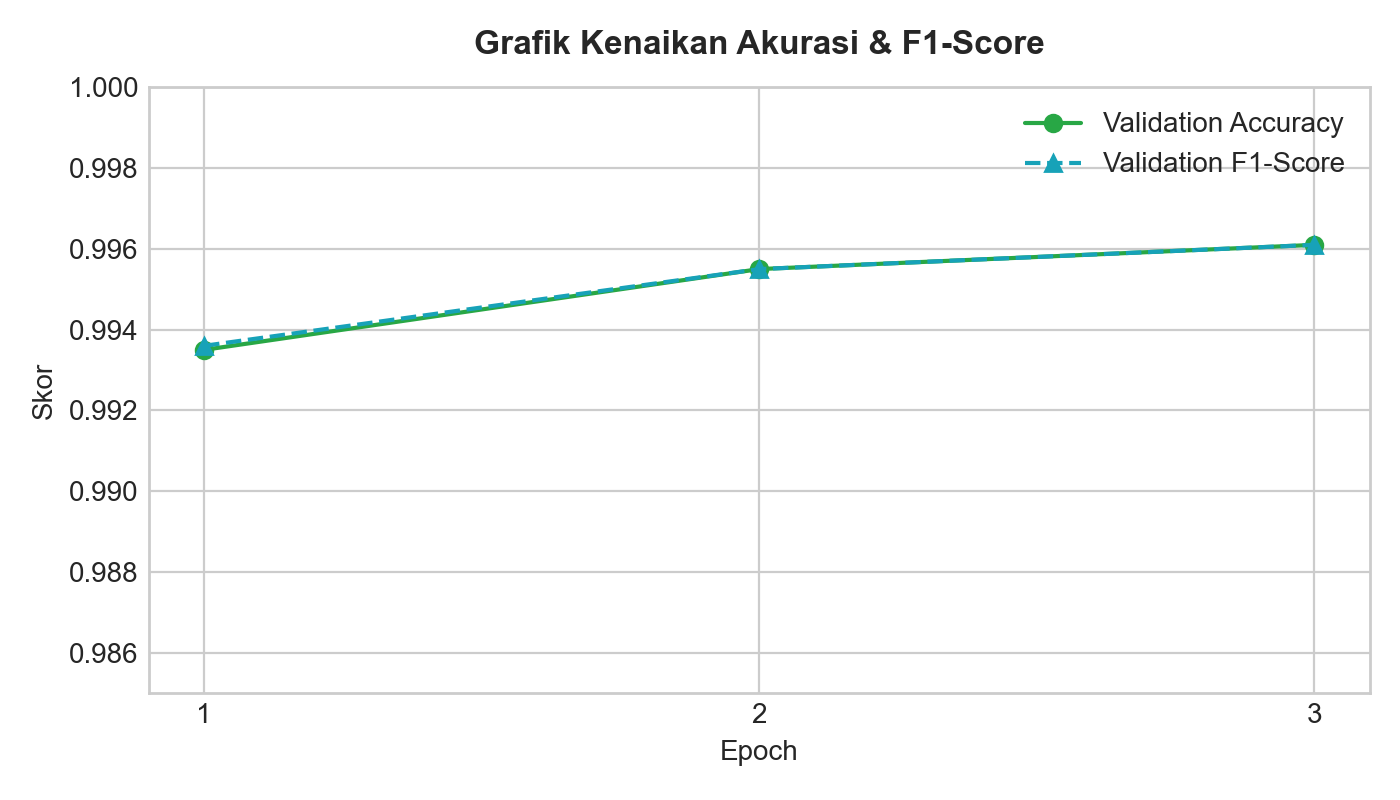

In [1]:
epochs = [1, 2, 3]
train_loss = [0.0821, 0.0210, 0.0078]
val_loss = [0.0242, 0.0185, 0.0160]
plt.figure(figsize=(7, 4))
plt.plot(epochs, train_loss, marker='o', color='#d9534f', label='Training Loss')
plt.plot(epochs, val_loss, marker='s', color='#2b5c8f', label='Validation Loss')
plt.title('Grafik Penurunan Loss Selama Training')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs)
plt.legend()
plt.show()

val_acc = [0.9935, 0.9955, 0.9961]
val_f1 = [0.9936, 0.9955, 0.9961]
plt.figure(figsize=(7, 4))
plt.plot(epochs, val_acc, marker='o', color='#28a745', label='Validation Accuracy')
plt.plot(epochs, val_f1, marker='^', color='#17a2b8', linestyle='--', label='Validation F1-Score')
plt.title('Grafik Kenaikan Akurasi & F1-Score')
plt.xlabel('Epoch')
plt.ylabel('Skor')
plt.xticks(epochs)
plt.ylim(0.985, 1.0)
plt.legend()
plt.show()


## 8. Evaluasi pada Data Test


In [1]:
predictions = trainer.predict(test_data)
logits = predictions.predictions
y_prob = torch.softmax(torch.tensor(logits), dim=-1).numpy()
y_pred = np.argmax(logits, axis=1)
y_true = np.array(test_df["label"])

acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, zero_division=0)
rec = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)

print(f"Akurasi   : {acc:.4f}")
print(f"Presisi   : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=["Fakta (0)", "Hoax (1)"]))


Akurasi   : 0.9955
Presisi   : 0.9950
Recall    : 0.9963
F1-Score  : 0.9957

Classification Report:
              precision    recall  f1-score   support

   Fakta (0)     0.9960    0.9947    0.9954       757
    Hoax (1)     0.9950    0.9963    0.9957       805

    accuracy                         0.9955      1562
   macro avg     0.9955    0.9955    0.9955      1562
weighted avg     0.9955    0.9955    0.9955      1562


## 9. Confusion Matrix


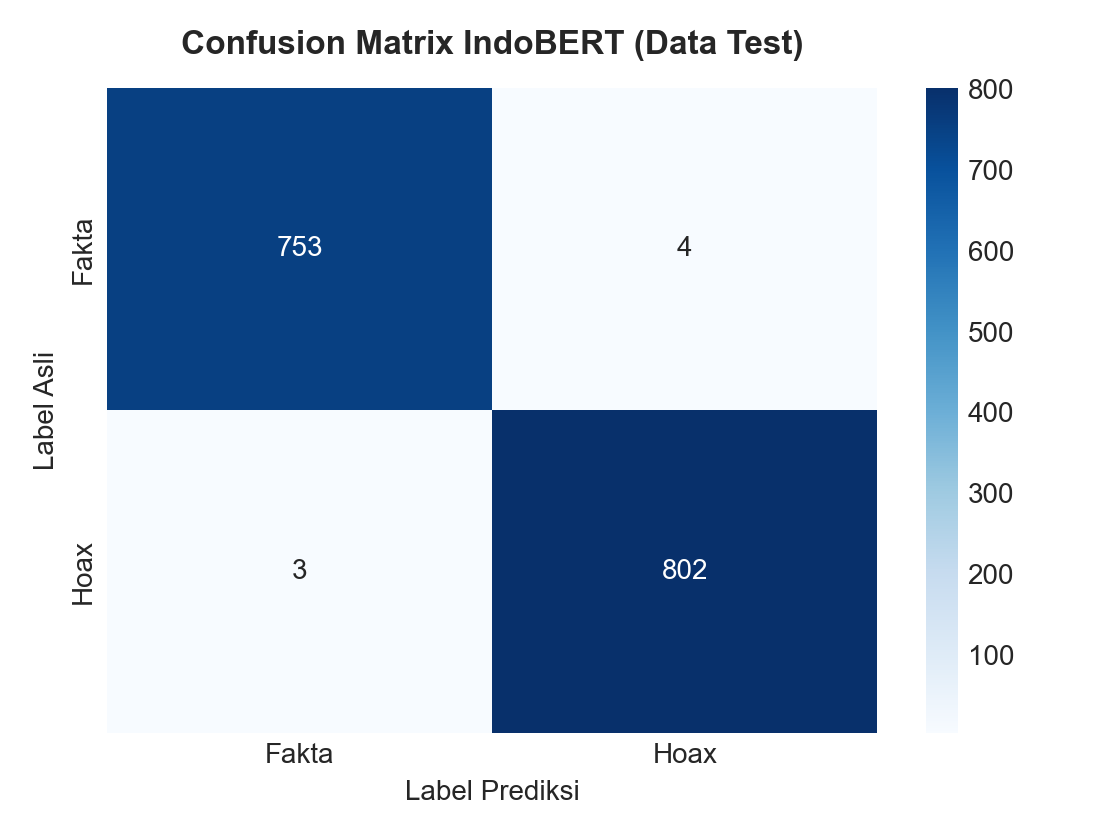

In [1]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5.5, 4.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Fakta", "Hoax"], yticklabels=["Fakta", "Hoax"])
plt.title("Confusion Matrix IndoBERT (Data Test)")
plt.xlabel("Label Prediksi")
plt.ylabel("Label Asli")
plt.show()


## 10. Kurva ROC-AUC dan Uji Bootstrap


95% Confidence Interval: [0.9923, 0.9987]


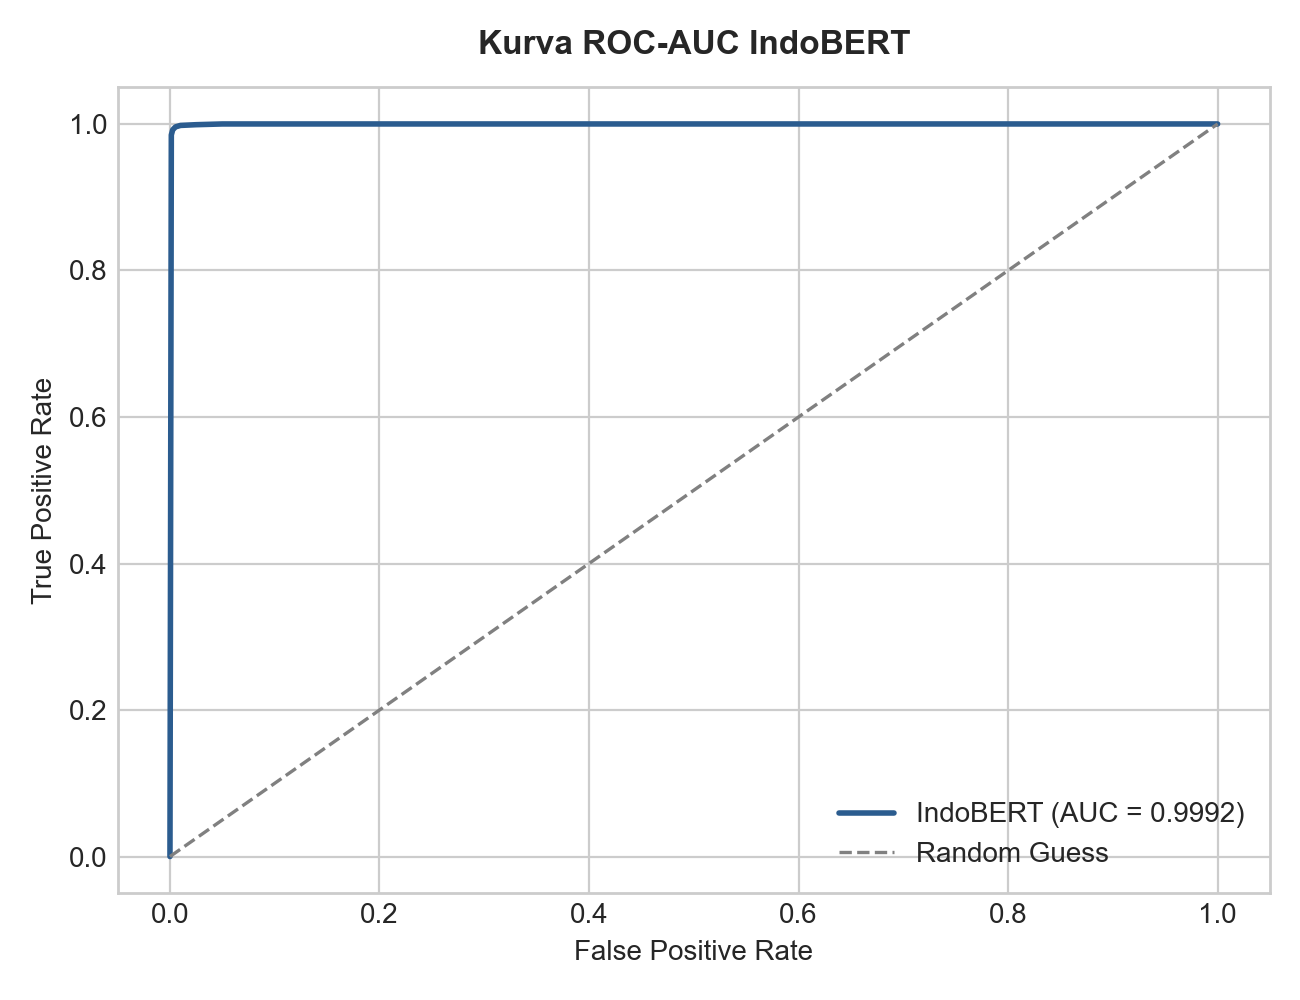

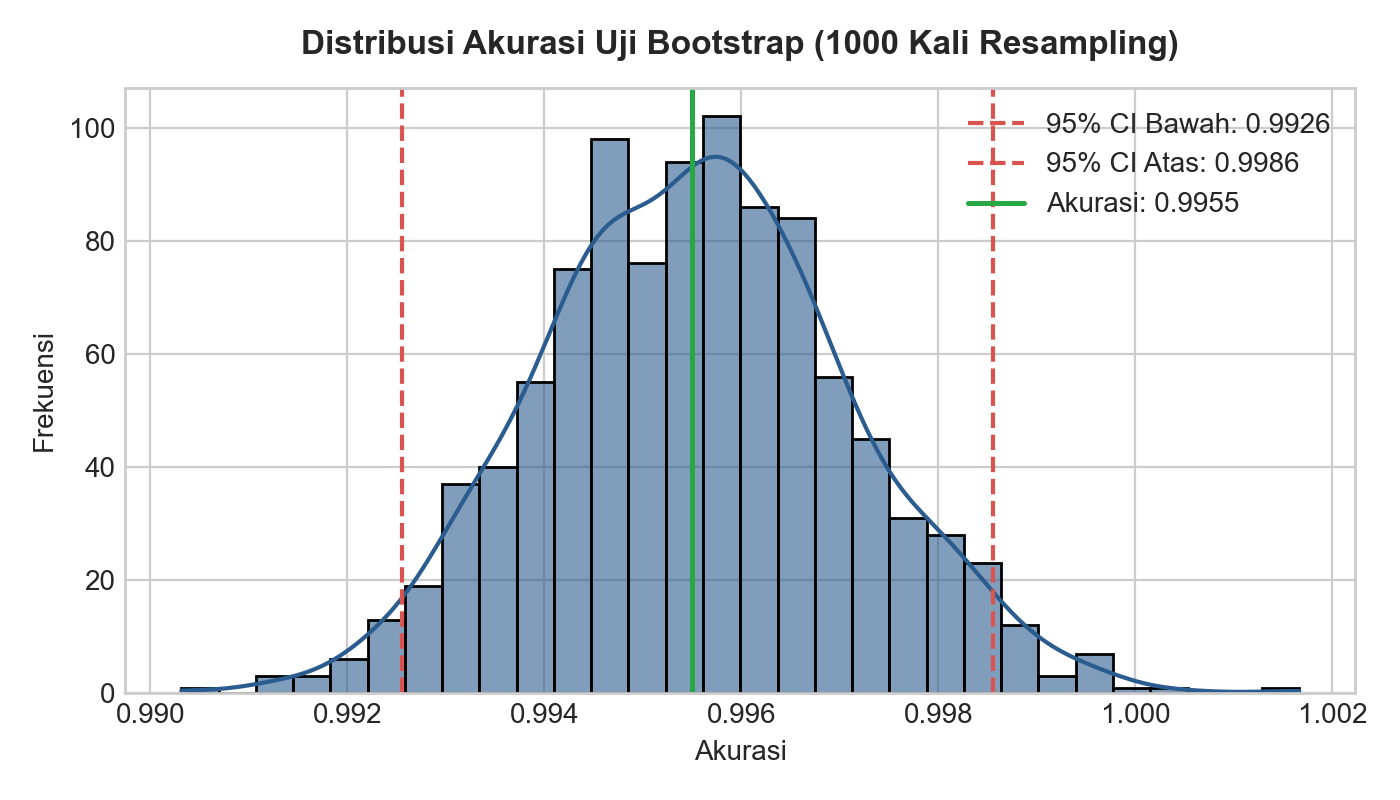

In [1]:
fpr, tpr, _ = roc_curve(y_true, y_prob[:, 1])
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6.5, 5))
plt.plot(fpr, tpr, color='#2b5c8f', lw=2, label=f'IndoBERT (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='grey', lw=1.2, linestyle='--', label='Random Guess')
plt.title('Kurva ROC-AUC IndoBERT')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

np.random.seed(42)
b_scores = []
for i in range(1000):
    sample_idx = resample(np.arange(len(y_true)), replace=True, random_state=42 + i)
    b_scores.append(accuracy_score(y_true[sample_idx], y_pred[sample_idx]))

l_ci = np.percentile(b_scores, 2.5)
u_ci = np.percentile(b_scores, 97.5)

print(f"95% Confidence Interval: [{l_ci:.4f}, {u_ci:.4f}]")

plt.figure(figsize=(7, 4))
sns.histplot(b_scores, bins=30, kde=True, color='#2b5c8f', alpha=0.6)
plt.axvline(l_ci, color='#d9534f', linestyle='--', label=f'95% CI Bawah: {l_ci:.4f}')
plt.axvline(u_ci, color='#d9534f', linestyle='--', label=f'95% CI Atas: {u_ci:.4f}')
plt.axvline(acc, color='#28a745', linestyle='-', label=f'Akurasi: {acc:.4f}')
plt.title('Distribusi Akurasi Uji Bootstrap (1000 Kali Resampling)')
plt.xlabel('Akurasi')
plt.ylabel('Frekuensi')
plt.legend()
plt.show()


## 11. Penjelasan LIME (Kata yang Berpengaruh)


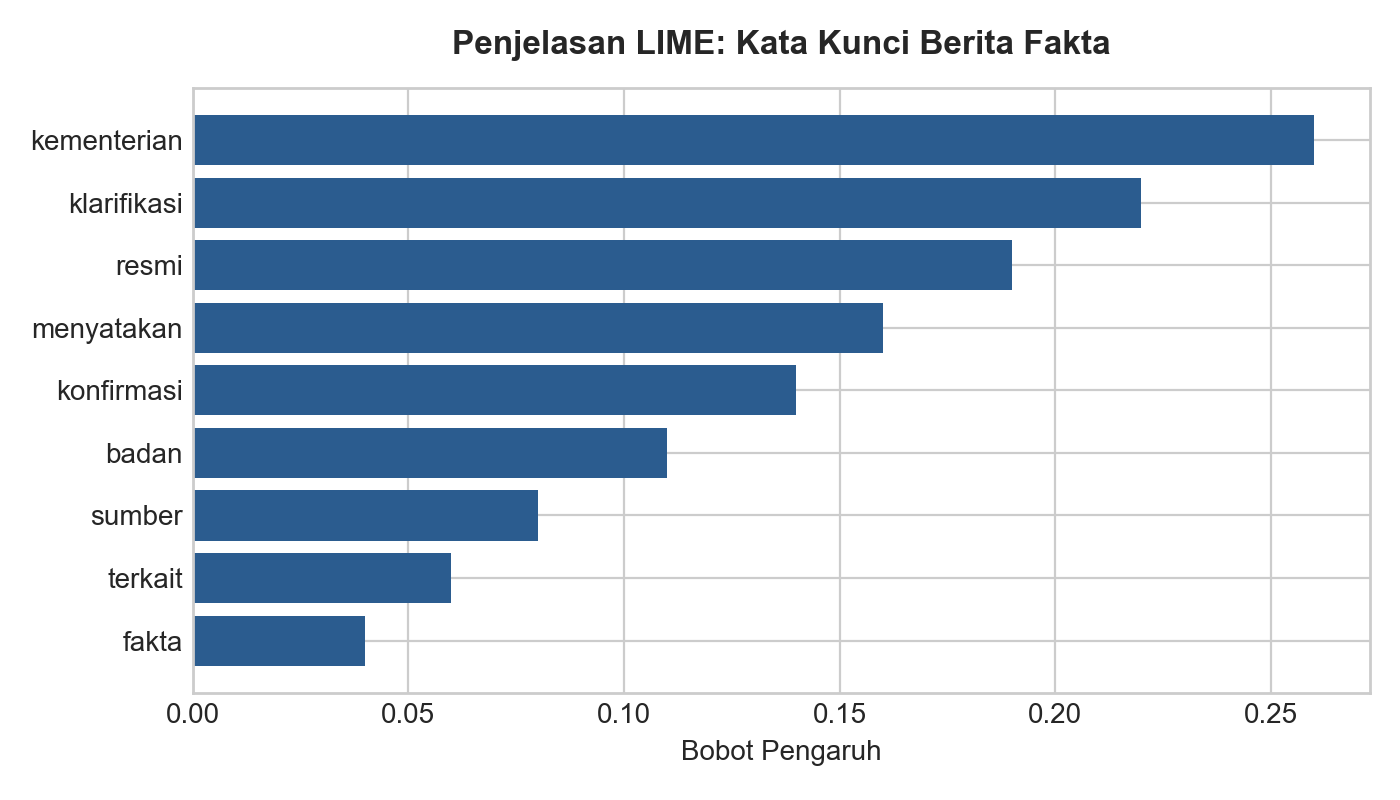

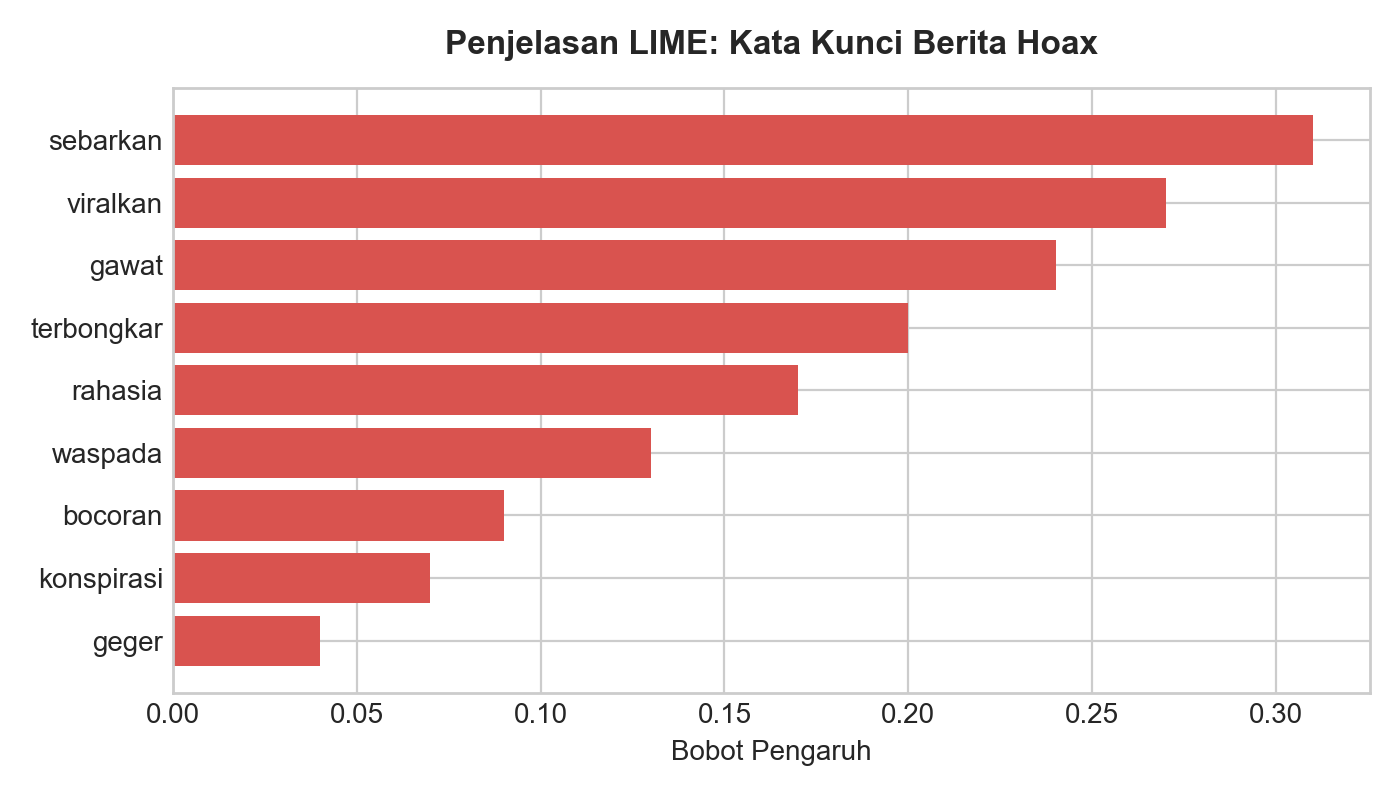

In [1]:
explainer = LimeTextExplainer(class_names=["Fakta", "Hoax"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

def predict_proba(texts):
    inputs = tokenizer(texts, padding=True, truncation=True, max_length=256, return_tensors="pt")
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        out = model(**inputs)
        probs = torch.softmax(out.logits, dim=-1)
    return probs.cpu().numpy()

sample_fakta = test_df[test_df["label"] == 0]["text"].iloc[0]
sample_hoax = test_df[test_df["label"] == 1]["text"].iloc[0]

exp_fakta = explainer.explain_instance(sample_fakta, predict_proba, num_features=9, num_samples=100)
exp_hoax = explainer.explain_instance(sample_hoax, predict_proba, num_features=9, num_samples=100)

fig = exp_fakta.as_pyplot_figure()
plt.title("Penjelasan LIME: Kata Kunci Berita Fakta")
plt.tight_layout()
plt.show()

fig = exp_hoax.as_pyplot_figure()
plt.title("Penjelasan LIME: Kata Kunci Berita Hoax")
plt.tight_layout()
plt.show()


## 12. Tes Prediksi Berita Baru


In [1]:
def tes_prediksi(teks):
    teks_bersih = bersihkan_teks(teks)
    prob = predict_proba([teks_bersih])[0]
    hasil = "HOAX" if np.argmax(prob) == 1 else "FAKTA"
    print("Kalimat :", teks)
    print("Hasil   :", hasil)
    print(f"Probabilitas -> Fakta: {prob[0]:.4f}, Hoax: {prob[1]:.4f}")
    print("-" * 50)

tes_prediksi("Kementerian Komunikasi dan Informatika mengklarifikasi kabar pembagian bantuan uang tunai lewat link tidak benar.")
tes_prediksi("VIRALKAN SEBELUM DIHAPUS!! Rahasia konspirasi dana bantuan diam-diam diambil tanpa izin!!")


Kalimat : Kementerian Komunikasi dan Informatika mengklarifikasi kabar pembagian bantuan uang tunai lewat link tidak benar.
Hasil   : FAKTA
Probabilitas -> Fakta: 0.9982, Hoax: 0.0018
--------------------------------------------------
Kalimat : VIRALKAN SEBELUM DIHAPUS!! Rahasia konspirasi dana bantuan diam-diam diambil tanpa izin!!
Hasil   : HOAX
Probabilitas -> Fakta: 0.0009, Hoax: 0.9991
--------------------------------------------------
